# Experimentación y Visualización de Redes ER
Este notebook te permitirá cargar un archivo `.apx` de tu carpeta de grafos Erdős-Rényi (ER), visualizar su topología utilizando `networkx` y calcular sus conjuntos libres de conflicto usando `pygarg`.

In [1]:
import sys
from pathlib import Path
import time
import networkx as nx
import matplotlib.pyplot as plt

# Configurar la ruta para que Python encuentre 'src/pygarg'
# Asumimos que vas a colocar este notebook en la carpeta 'exp/'
ruta_exp = Path().resolve()
ruta_raiz = ruta_exp.parent
ruta_src = ruta_raiz / "src"

if str(ruta_src) not in sys.path:
    sys.path.append(str(ruta_src))

# Importar los módulos de la librería pygarg
import pygarg.dung.apx_parser
import pygarg.dung.solver

print("Librerías cargadas correctamente y ruta src vinculada.")

Matplotlib is building the font cache; this may take a moment.


Librerías cargadas correctamente y ruta src vinculada.


In [10]:
archivo_prueba = ruta_exp / "instances" / "BA" / "BA-numArg14-pbCycle0-0.apx"
archivo_prueba

PosixPath('/Users/andres/Desktop/IJCAI/Experiments/pygarg/exp/instances/BA/BA-numArg14-pbCycle0-0.apx')

## 1. Cargar la Instancia ER
Asegúrate de cambiar el nombre del archivo por uno que exista en tu carpeta `ER`.

In [11]:
# Ruta al archivo .apx específico dentro de ER
# ¡CAMBIA 'nombre_de_tu_archivo.apx' POR UN ARCHIVO REAL!

# Si el archivo no existe, usaremos un pequeño grafo de prueba
if not archivo_prueba.exists():
    print(f"ATENCIÓN: No se encontró {archivo_prueba.name}. Usando un grafo de ejemplo...")
    args = ['a', 'b', 'c', 'd', 'e']
    atts = [('a', 'b'), ('c', 'b'), ('c', 'd'), ('d', 'c'), ('d', 'e')]
else:
    args, atts = pygarg.dung.apx_parser.parse(str(archivo_prueba))
    print(f"Grafo cargado: {archivo_prueba.name}")

print(f"Nodos (Argumentos): {len(args)} | Aristas (Ataques): {len(atts)}")

ATENCIÓN: No se encontró BA-numArg14-pbCycle0-0.apx. Usando un grafo de ejemplo...
Nodos (Argumentos): 5 | Aristas (Ataques): 5


## 2. Visualizar el Argumentation Framework (AF)
Utilizaremos `networkx` para crear un grafo dirigido. Las flechas rojas representan los ataques.

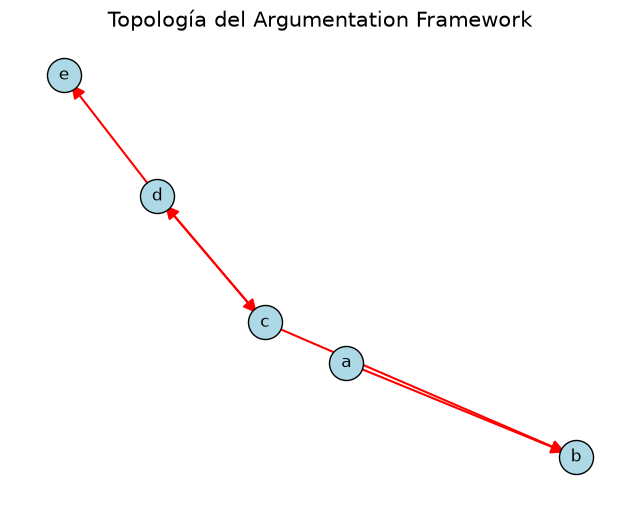

In [12]:
# Crear un grafo dirigido
G = nx.DiGraph()
G.add_nodes_from(args)
G.add_edges_from(atts)

# Configurar el estilo del gráfico
plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G, seed=42)  # Algoritmo para separar los nodos

# Dibujar nodos
nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=600, edgecolors='black')
nx.draw_networkx_labels(G, pos, font_size=12)

# Dibujar aristas (ataques)
nx.draw_networkx_edges(G, pos, edgelist=G.edges(), arrowstyle='-|>', arrowsize=20, edge_color='red', width=1.5)

plt.title("Topología del Argumentation Framework", fontsize=15)
plt.axis("off")
plt.show()

## 3. Simulación de Explosión Combinatoria
Calculamos todos los conjuntos libres de conflicto (CF). Al medirlos, podemos justificar las afirmaciones empíricas sobre la complejidad de calcular las facetas del complejo simplicial.

In [13]:
inicio = time.time()

# Ejecutar el solver de pygarg
extensiones_cf = list(pygarg.dung.solver.extension_enumeration(args, atts, 'CF'))

tiempo_total = time.time() - inicio

print(f"Tiempo de cómputo: {tiempo_total:.5f} segundos")
print(f"Total de conjuntos libres de conflicto (CF): {len(extensiones_cf)}")
print(f"Muestra de las primeras 5 extensiones encontradas: {extensiones_cf[:5]}")

Tiempo de cómputo: 0.00046 segundos
Total de conjuntos libres de conflicto (CF): 13
Muestra de las primeras 5 extensiones encontradas: [[], ['b'], ['b', 'd'], ['d'], ['c']]
